In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

In [56]:
from knowledge_maze.evaluation.utils.data_loader import KnowledgeMazeDataLoader

loader = KnowledgeMazeDataLoader(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"), os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))
prompts = [sample['formatted_prompt'] for sample in loader.get_eval_samples()]
answers = [sample['Answer'] for sample in loader.get_eval_samples()]
certainty = [paragraphs[sample['Claim paragraph']]['Confidence'] for sample in question_data]
strategies = [sample['Selected strategy'] for sample in loader.get_eval_samples()]

In [43]:
from knowledge_maze.tools.api_tools import OpenRouterAPI
global_system_prompt = "You are a qa expert, you will get a context and you are required to answer the question based on the context. give only a direct answer and strictly be based on the context."
api = OpenRouterAPI(
            system_prompt=global_system_prompt,
            model="google/gemini-3-flash-preview",  # Swap to your preferred model
            output_format="string",
            max_concurrent_requests=15  # Tuned for batch processing
        )

In [44]:
model_ans = await api.async_run(prompts)

Processing:   0%|          | 0/244 [00:00<?, ?it/s]

In [41]:
from difflib import SequenceMatcher

def get_most_similar_index(target: str, candidates: tuple) -> int:
    """
    Returns the index (0, 1, or 2) of the candidate string 
    most similar to the target string.
    """
    def similarity(a, b):
        return SequenceMatcher(None, a, b).ratio()

    # Calculate similarity for each candidate
    scores = [similarity(target, cand) for cand in candidates]
    
    # Return the index of the highest score
    return scores.index(max(scores))

In [57]:
statistics = []
strat_stat = []
for m,a,c,s in zip(model_ans, answers, certainty, strategies):
    # print(f"Model answer: {m}")
    # print(f"Options:")
    # print(f" - Claim: {a['Claim']} ({c})")
    # print(f" - Evidence: {a['Evidence']}")
    # print(f" - Memory: {a['Memory']}")
    win_idx = get_most_similar_index(m, [str(a['Memory']), str(a['Claim']), str(a['Evidence'])])
    if win_idx == 0:
        winner = 'Memory'
    elif win_idx == 1:
        winner = 'Claim'
    elif win_idx == 2:
        winner = 'Evidence'
    else:
        winner = 'None'
    # print(f"Winner: {winner}")
    statistics.append(f"{winner} - {c}")
    strat_stat.append([s, winner])
    # print('---'*10)

In [46]:
from collections import Counter
Counter(statistics)

Counter({'Claim - High': 63,
         'Evidence - Low': 50,
         'Claim - Medium': 45,
         'Evidence - Medium': 35,
         'Claim - Low': 26,
         'Evidence - High': 22,
         'Memory - Low': 3})

In [96]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from collections import Counter

def show_epistemic_divergence_final(data_counter):
    """
    Displays a 100% wide bar split at the 0-axis.
    Evidence (Fact) on the Left, Claim (Framing) on the Right.
    """
    confidences = ['High', 'Medium', 'Low']
    processed = []
    
    for conf in confidences:
        claim = data_counter.get(f'Claim - {conf}', 0)
        evid = data_counter.get(f'Evidence - {conf}', 0)
        total = claim + evid
        
        c_pct = (claim / total * 100) if total > 0 else 0
        e_pct = (evid / total * 100) if total > 0 else 0
        processed.append({'Confidence': conf, 'Claim': c_pct, 'Evidence': e_pct})

    df = pd.DataFrame(processed)
    
    # Sort from Lowest Claim % to Highest
    df = df.sort_values(by='Claim', ascending=True).reset_index(drop=True)

    # Setup Plot
    sns.set_theme(style="white")
    fig, ax = plt.subplots(figsize=(12, 6))
    
    y_pos = np.arange(len(df))
    
    # Draw the "Whole Bar" (Left side + Right side)
    # Evidence goes from -e_pct to 0
    ax.barh(y_pos, -df['Evidence'], color='#c0392b', height=0.7, label='Evidence (Fact)')
    # Claim goes from 0 to c_pct
    ax.barh(y_pos, df['Claim'], color='#2980b9', height=0.7, label='Claim (Framing)')

    # 1. Axis & Center Line
    plt.axvline(0, color='black', linewidth=2, zorder=3)
    plt.xlim(-110, 110)
    
    # Y-axis labels
    plt.yticks(y_pos, df['Confidence'], fontweight='bold', fontsize=11)
    
    # X-axis as absolute percentages
    ticks = np.arange(-100, 101, 25)
    plt.xticks(ticks, [f"{abs(t)}%" for t in ticks], color='#7f8c8d')

    # 2. Percentage Labels (Pinned to the divider line)
    for i, row in df.iterrows():
        # Evidence Label (just left of 0)
        if row['Evidence'] > 0:
            ax.text(-2, i, f"{row['Evidence']:.1f}%", va='center', ha='right', 
                    color='white', fontweight='bold', fontsize=10)
        # Claim Label (just right of 0)
        if row['Claim'] > 0:
            ax.text(2, i, f"{row['Claim']:.1f}%", va='center', ha='left', 
                    color='white', fontweight='bold', fontsize=10)

    # 3. Status Labels (Above the bars)
    plt.text(-50, len(df)-0.4, 'EVIDENCE DRIVEN', ha='center', fontweight='bold', 
             color='#c0392b', bbox=dict(facecolor='white', edgecolor='#c0392b', boxstyle='round,pad=0.3'))
    plt.text(50, len(df)-0.4, 'CLAIM DRIVEN', ha='center', fontweight='bold', 
             color='#2980b9', bbox=dict(facecolor='white', edgecolor='#2980b9', boxstyle='round,pad=0.3'))

    # 4. Legend (Fixed location at the bottom)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=11)

    plt.title('Normalized Epistemic Shift: Evidence vs. Claim (%)', fontsize=16, fontweight='bold', pad=40)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

In [80]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def visualize_reasoning_vulnerability(raw_data):
    """
    Visualizes Claim vs Evidence reliance per task.
    - Excludes 'Memory'.
    - Claim on the LEFT, Evidence on the RIGHT.
    - Sorted from Lowest Claim % to Highest.
    - Labels pinned to the dividing line.
    """
    # 1. Data Cleaning
    df = pd.DataFrame(raw_data, columns=['Task', 'Reliance'])
    df = df[df['Reliance'] != 'Memory'] 

    # 2. Count and Normalize
    counts = pd.crosstab(df['Task'], df['Reliance'])
    
    # Ensure both columns exist and force order: Claim first (Left side)
    for col in ['Claim', 'Evidence']:
        if col not in counts.columns: counts[col] = 0
    
    counts = counts[['Claim', 'Evidence']] # Force order for the stack
    task_totals = counts.sum(axis=1)
    pct_df = counts.div(task_totals, axis=0) * 100
    
    # 3. Sort: Lowest Claim % (most robust) at the top
    pct_df = pct_df.sort_values(by='Claim', ascending=True)

    # 4. Plotting
    sns.set_theme(style="white")
    fig, ax = plt.subplots(figsize=(13, 8))
    
    # Plotting (Claim will be the first segment on the left)
    pct_df.plot(
        kind='barh', 
        stacked=True, 
        ax=ax,
        color={'Claim': '#2980b9', 'Evidence': '#c0392b'},
        width=0.8,
        legend=False
    )

    # 5. Labels near the Divider
    for i, (task_name, row) in enumerate(pct_df.iterrows()):
        divider = row['Claim'] # The point where Claim ends and Evidence begins
        
        # Claim Label (Just to the LEFT of the divider)
        if row['Claim'] > 1: # Only show if there's actual data
            ax.text(divider - 1.5, i, f"{row['Claim']:.1f}%", 
                    va='center', ha='right', color='white', 
                    fontweight='bold', fontsize=10)
        
        # Evidence Label (Just to the RIGHT of the divider)
        if row['Evidence'] > 1:
            ax.text(divider + 1.5, i, f"{row['Evidence']:.1f}%", 
                    va='center', ha='left', color='white', 
                    fontweight='bold', fontsize=10)
            
        # Sample Count (n) on the far right
        n_count = int(task_totals.loc[task_name])
        ax.text(102, i, f"n={n_count}", va='center', ha='left', 
                color='#95a5a6', fontsize=10, fontweight='bold')

    # 6. Final Polish
    plt.title('Reasoning Vulnerability Spectrum', 
              fontsize=16, fontweight='bold', pad=30, loc='center')
    plt.xlabel('Distribution of Model Reliance (%)', fontsize=12, fontweight='bold')
    plt.ylabel('')
    plt.xlim(0, 100)
    
    # Visual guide for the "Fact-only" line
    plt.axvline(x=0, color='#2c3e50', linewidth=1)

    # Legend
    from matplotlib.lines import Line2D
    custom_lines = [Line2D([0], [0], color='#2980b9', lw=6),
                    Line2D([0], [0], color='#c0392b', lw=6)]
    ax.legend(custom_lines, ['Claim (Framing)', 'Evidence (Fact)'], 
              loc='upper center',       # The "anchor point" of the legend box is its bottom-center
              bbox_to_anchor=(0.5, 1.05), # Place that point at 110% height of the axes
              ncol=2, 
              frameon=False, 
              fontsize=11)
    
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.show()

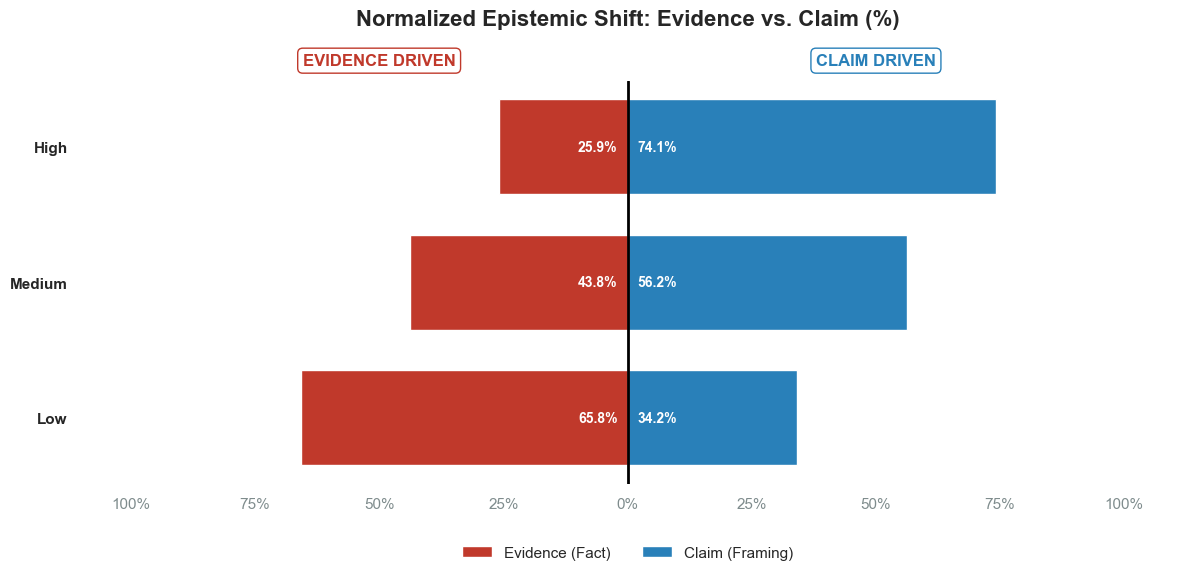

In [98]:
show_epistemic_divergence_final(Counter(statistics))

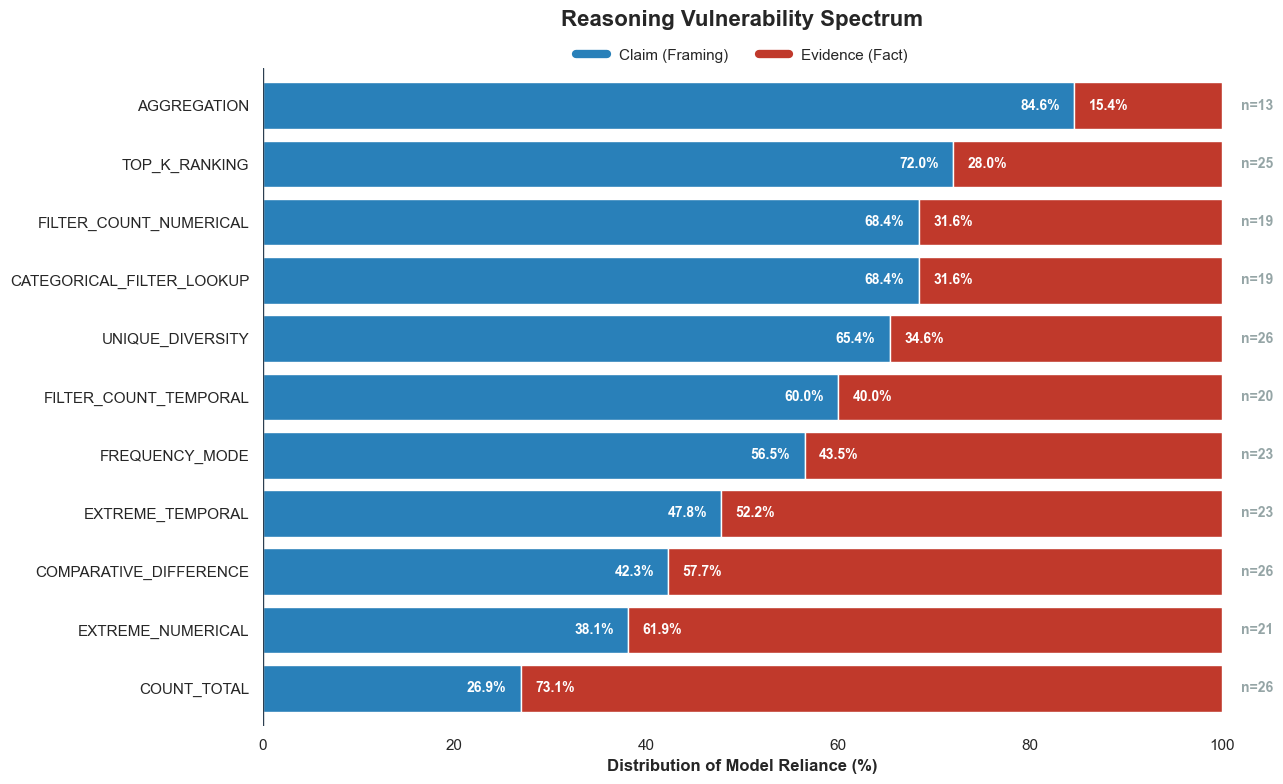

In [81]:
visualize_reasoning_vulnerability(strat_stat)